<a href="https://colab.research.google.com/github/garcialvarez/HAR/blob/main/06_cnn2d_tiempo_frecuencia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 — CNN 2D sobre espectrogramas (familia B: tiempo-frecuencia)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/06_cnn2d_tiempo_frecuencia.ipynb)

**Entrega 2 — Notebook 6 de 7.** Segunda **familia de modelos, con una modalidad de información
distinta**: en vez de alimentar la serie temporal a la red (notebooks 04 y 05), cada canal se transforma
en un **espectrograma** (STFT, ver notebook 02) y una CNN 2D lo procesa como una imagen *frecuencia × tiempo*.
La pregunta de la retroalimentación es: ¿qué modalidad generaliza mejor a sujetos nuevos?

**Experimentos (iteraciones):**

| Id | Entrada | Forma por ventana |
|---|---|---|
| B1 | STFT `nperseg = 32` de los 9 canales | 17 × 25 × 9 |
| B2 | STFT `nperseg = 64` de los 9 canales (más resolución en frecuencia) | 33 × 9 × 9 |
| B3 | STFT `nperseg = 32` de 12 canales (+ magnitudes) | 17 × 25 × 12 |

**Protocolo** idéntico al de los notebooks 04 y 05: validación por sujeto dentro del train, normalizador
ajustado solo con entrenamiento, test oficial al final y media ± desviación sobre 3 semillas.

**Entradas:** dataset UCI HAR. **Salidas:** métricas en este notebook y en `results/` (local, no versionado).

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

Descargando dataset (intento 1/3)...
Descargado: 61.0 MB


PosixPath('/content/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from data_loader import load_raw_signals
from evaluation import plot_confusion_matrix, plot_history
from preprocessing import CLASS_NAMES, encode_labels
from training import evaluate_keras, fit_keras, prepare_stft_inputs

pd.set_option("display.width", 130)
SEEDS = (42, 43, 44)

X_tr_raw, y_tr_s, s_tr = load_raw_signals("train")
X_te_raw, y_te_s, _ = load_raw_signals("test")
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values
print("train:", X_tr_raw.shape, "| test:", X_te_raw.shape, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

train: (7352, 128, 9) | test: (2947, 128, 9) | GPU: False


## 1. Arquitectura

```
Entrada (F, T', C)  — espectrograma frecuencia × tiempo × canales
 → [Conv2D(32, 3×3) → BatchNorm → ReLU] → MaxPool(2×2)
 → [Conv2D(64, 3×3) → BatchNorm → ReLU] → MaxPool(2×2)
 → [Conv2D(128, 3×3) → BatchNorm → ReLU]
 → Flatten → Dropout(0.5) → Dense(64) → Dropout(0.5) → Dense(6, softmax)
```

A diferencia de la CNN 1D, aquí **no** se usa `GlobalAveragePooling`: promediar sobre el eje de
frecuencias borraría *en qué banda* está la energía, que es justo lo que distingue caminar de subir
escaleras. `Flatten` conserva esa posición.

In [5]:
def build_cnn2d(input_shape):
    inp = keras.Input(input_shape)
    x = inp
    for filtros, pool in [(32, True), (64, True), (128, False)]:
        x = layers.Conv2D(filtros, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        if pool:
            x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name="cnn2d")


for nombre, forma in [("B1", (17, 25, 9)), ("B2", (33, 9, 9)), ("B3", (17, 25, 12))]:
    print(f"{nombre} {forma}: {build_cnn2d(forma).count_params():,} parámetros")

B1 (17, 25, 9): 292,934 parámetros
B2 (33, 9, 9): 227,398 parámetros
B3 (17, 25, 12): 293,798 parámetros


## 2. Entrenamiento de los experimentos

Mismo procedimiento que en los notebooks anteriores (Adam, `EarlyStopping` sobre la pérdida de
validación con paciencia 8, `ReduceLROnPlateau`, máximo 40 épocas).

In [6]:
EXPERIMENTOS = {          # id: (nperseg, variante de canales)
    "B1": (32, "raw"),
    "B2": (64, "raw"),
    "B3": (32, "mag"),
}

runs, histories = {}, {}
t_total = time.perf_counter()

for exp, (nperseg, variante) in EXPERIMENTOS.items():
    d = prepare_stft_inputs(X_tr_raw, X_te_raw, s_tr, nperseg=nperseg, variant=variante)
    ytr, yva = y_tr[d["tr"]], y_tr[d["va"]]
    print(f"{exp}: entrada {d['Xtr'].shape[1:]}")
    runs[exp] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = build_cnn2d(d["Xtr"].shape[1:])
        hist, seg = fit_keras(model, d["Xtr"], ytr, d["Xva"], yva, epochs=40)
        mejor = int(np.argmin(hist.history["val_loss"]))
        res = evaluate_keras(f"06_{exp}_s{seed}", "tiempo_frecuencia_cnn2d", model, d["Xte"], y_te, CLASS_NAMES, seg,
                             notes=f"{exp}: nperseg={nperseg}, canales={variante}, semilla={seed}")
        res.update(val_loss=hist.history["val_loss"][mejor], val_acc=hist.history["val_accuracy"][mejor],
                   epocas=len(hist.history["loss"]))
        runs[exp].append(res)
        if seed == SEEDS[0]:
            histories[exp] = hist
print(f"\nTiempo total: {(time.perf_counter() - t_total) / 60:.1f} min")

B1: entrada (17, 25, 9)
[06_B1_s42] accuracy=0.9484  F1 macro=0.9489  latencia=1.26 ms/ventana
[06_B1_s43] accuracy=0.8982  F1 macro=0.8983  latencia=1.29 ms/ventana
[06_B1_s44] accuracy=0.9430  F1 macro=0.9433  latencia=1.28 ms/ventana
B2: entrada (33, 9, 9)
[06_B2_s42] accuracy=0.9308  F1 macro=0.9296  latencia=1.20 ms/ventana
[06_B2_s43] accuracy=0.8904  F1 macro=0.8863  latencia=1.19 ms/ventana
[06_B2_s44] accuracy=0.9321  F1 macro=0.9319  latencia=1.22 ms/ventana
B3: entrada (17, 25, 12)
[06_B3_s42] accuracy=0.9332  F1 macro=0.9330  latencia=1.29 ms/ventana
[06_B3_s43] accuracy=0.8612  F1 macro=0.8464  latencia=1.28 ms/ventana
[06_B3_s44] accuracy=0.9070  F1 macro=0.9054  latencia=1.29 ms/ventana

Tiempo total: 25.2 min


## 3. Resultados por experimento

,nperseg,canales,val acc,test acc,F1 macro test,parámetros,latencia (ms/ventana),tamaño (KB),épocas (media),entrenamiento (s)
B1,32,raw,0.9411 ± 0.0233,0.9299 ± 0.0225,0.9302 ± 0.0227,292934,1.274,1144.0,25.3,213.7
B2,64,raw,0.9204 ± 0.0118,0.9178 ± 0.0194,0.9159 ± 0.0210,227398,1.204,888.0,16.0,93.3
B3,32,mag,0.9126 ± 0.0272,0.9005 ± 0.0297,0.8949 ± 0.0361,293798,1.287,1148.0,21.7,186.7


,semilla 42,semilla 43,semilla 44
B1,0.9484,0.8982,0.9430
B2,0.9308,0.8904,0.9321
B3,0.9332,0.8612,0.9070


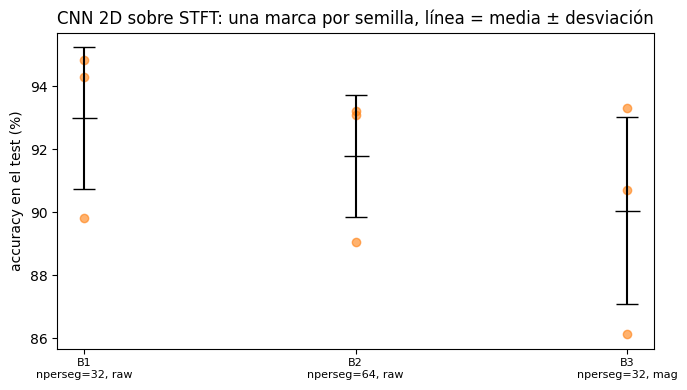

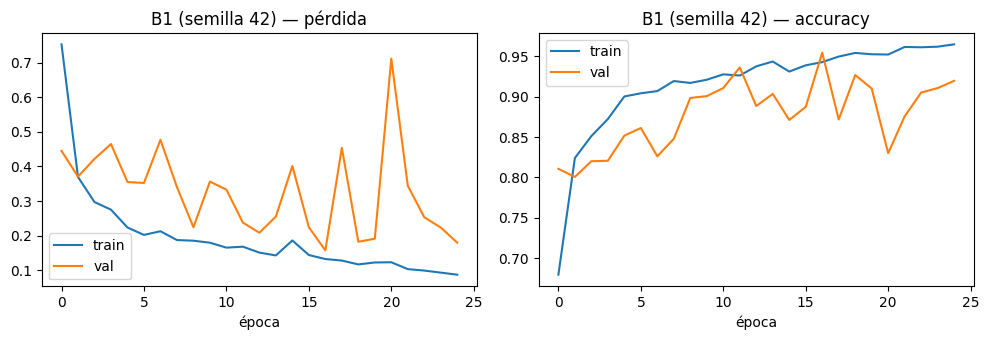

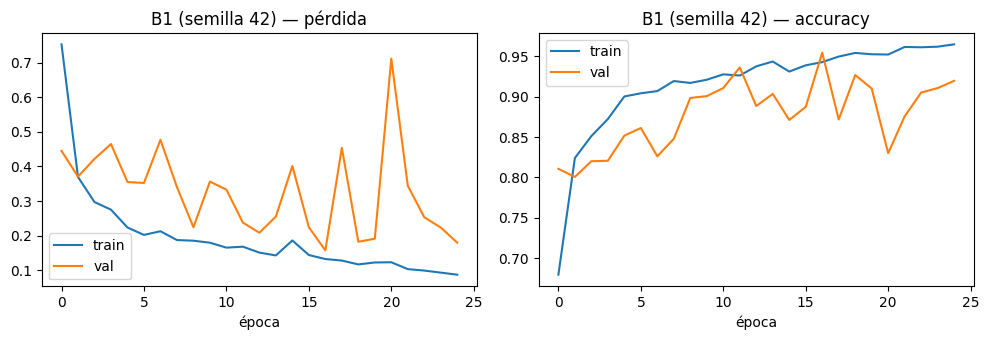

In [7]:
def ms(exp, clave):
    v = np.array([r[clave] for r in runs[exp]], dtype=float)
    return v.mean(), v.std()


filas = {}
for exp, (nperseg, variante) in EXPERIMENTOS.items():
    fila = {"nperseg": nperseg, "canales": variante}
    for etiqueta, clave in [("val acc", "val_acc"), ("test acc", "accuracy"), ("F1 macro test", "f1_macro")]:
        m, s = ms(exp, clave)
        fila[etiqueta] = f"{m:.4f} ± {s:.4f}"
    fila["parámetros"] = runs[exp][0]["n_params"]
    fila["latencia (ms/ventana)"] = round(ms(exp, "latency_single_ms")[0], 3)
    fila["tamaño (KB)"] = round(runs[exp][0]["model_size_kb"], 0)
    fila["épocas (media)"] = round(ms(exp, "epocas")[0], 1)
    fila["entrenamiento (s)"] = round(ms(exp, "train_time_s")[0], 1)
    filas[exp] = fila
display(pd.DataFrame(filas).T)

display(pd.DataFrame({exp: [round(r["accuracy"], 4) for r in runs[exp]] for exp in EXPERIMENTOS},
                     index=[f"semilla {s}" for s in SEEDS]).T)

fig, ax = plt.subplots(figsize=(7, 4))
for k, exp in enumerate(EXPERIMENTOS):
    accs = [100 * r["accuracy"] for r in runs[exp]]
    ax.scatter([k] * len(accs), accs, color="C1", alpha=0.6, zorder=3)
    ax.errorbar(k, np.mean(accs), yerr=np.std(accs), fmt="_", color="k", capsize=8, markersize=18, zorder=4)
ax.set_xticks(range(len(EXPERIMENTOS)), [f"{e}\nnperseg={EXPERIMENTOS[e][0]}, {EXPERIMENTOS[e][1]}" for e in EXPERIMENTOS],
              fontsize=8)
ax.set_ylabel("accuracy en el test (%)")
ax.set_title("CNN 2D sobre STFT: una marca por semilla, línea = media ± desviación")
fig.tight_layout()
plt.show()

plot_history(histories["B1"], title="B1 (semilla 42)", save_name="06_curvas_B1.png")

## 4. Finalista de la familia y errores por clase

Se elige por la **menor pérdida de validación media** (no por el test).

Finalista de la familia CNN 2D: B1 (pérdida de validación media = 0.1588)


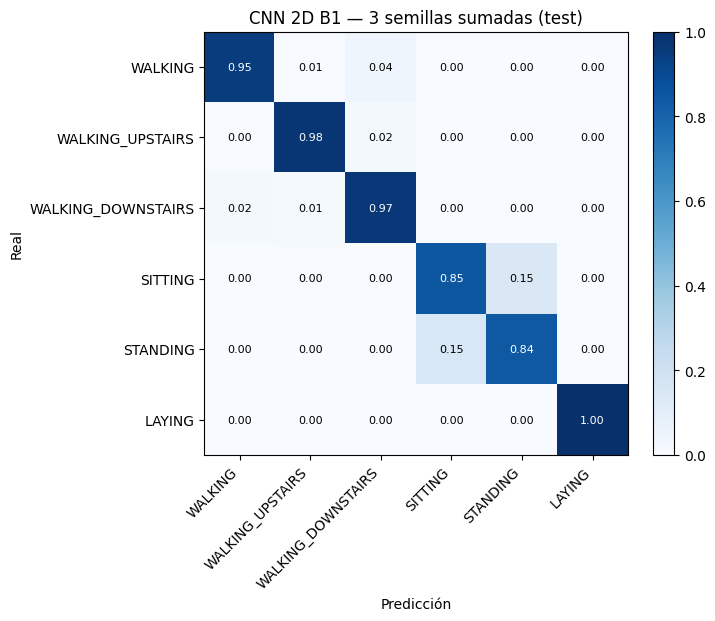

,tasa de falsos negativos
WALKING,0.049
WALKING_UPSTAIRS,0.024
WALKING_DOWNSTAIRS,0.032
SITTING,0.151
STANDING,0.157
LAYING,0.001


In [8]:
finalista = min(EXPERIMENTOS, key=lambda e: ms(e, "val_loss")[0])
print(f"Finalista de la familia CNN 2D: {finalista} (pérdida de validación media = {ms(finalista, 'val_loss')[0]:.4f})")

cm = np.sum([r["confusion_matrix"] for r in runs[finalista]], axis=0)
plot_confusion_matrix(cm, CLASS_NAMES, title=f"CNN 2D {finalista} — 3 semillas sumadas (test)",
                      save_name="06_confusion_finalista.png")

fn = pd.DataFrame({c: np.mean([r["false_negative_rate"][c] for r in runs[finalista]]) for c in CLASS_NAMES},
                  index=["tasa de falsos negativos"]).T
display(fn.round(3))

## Conclusiones

In [9]:
print("Accuracy en el test (media ± desviación entre semillas):")
for exp, (nperseg, variante) in EXPERIMENTOS.items():
    m, s = ms(exp, "accuracy")
    print(f"  {exp} (nperseg={nperseg}, {variante}): {100 * m:.2f} ± {100 * s:.2f} %")
conf = np.array(cm)
i, j = CLASS_NAMES.index("SITTING"), CLASS_NAMES.index("STANDING")
print(f"- En el finalista, SITTING↔STANDING = {100 * (conf[i, j] + conf[j, i]) / (conf.sum() - np.trace(conf)):.0f} % de los errores.")
va, te = ms(finalista, "val_acc")[0], ms(finalista, "accuracy")[0]
print(f"- Brecha de generalización: {100 * va:.1f} % (validación) frente a {100 * te:.1f} % (test).")
print("- La comparación con la familia del dominio del tiempo y con la línea base clásica está en el notebook 07.")

Accuracy en el test (media ± desviación entre semillas):
  B1 (nperseg=32, raw): 92.99 ± 2.25 %
  B2 (nperseg=64, raw): 91.78 ± 1.94 %
  B3 (nperseg=32, mag): 90.05 ± 2.97 %
- En el finalista, SITTING↔STANDING = 75 % de los errores.
- Brecha de generalización: 94.1 % (validación) frente a 93.0 % (test).
- La comparación con la familia del dominio del tiempo y con la línea base clásica está en el notebook 07.


**Lectura de los resultados.**

- **B3 (STFT con magnitudes) es el mejor y el más estable** entre las semillas; la ventaja sobre B1 es del
  mismo orden que la dispersión de B1, así que no es concluyente.
- **B2 (`nperseg = 64`) es el peor y el más variable:** duplicar la resolución en frecuencia a costa de
  quedarse con solo 9 pasos de tiempo no compensó (ese compromiso de resolución se describe en el notebook 02).
- **Mismo punto débil que las series temporales:** la mayoría de los errores son *sentado* ↔ *de pie*.
- Con ≈ 290 mil parámetros, la CNN 2D es unas cinco veces más grande que la CNN 1D (≈ 59 mil) y su
  latencia por ventana es algo mayor.

Siguiente: [`07_comparacion_y_validacion_sujetos.ipynb`](07_comparacion_y_validacion_sujetos.ipynb) —
se reentrenan los mejores modelos de cada familia, se comparan (precisión, latencia, tamaño) y se valida
con `GroupKFold` sobre los 30 sujetos.